# Smart Customer Support Ticket Intelligence System

An NLP-based machine learning project that automatically classifies customer support messages into their appropriate intent categories.

The project explores text preprocessing, feature extraction, traditional machine learning algorithms, and model evaluation to develop an effective customer query classification system.

## 1. Problem Statement

Customer support teams receive a large volume of queries related to payments, cards, bank transfers, account access, and other services. Manually categorizing these queries can be time-consuming.

The goal of this project is to build a machine learning system that predicts the intent of a customer message and helps automate the initial classification of support tickets.

This project focuses on **multi-class text classification**, where each input message is assigned to one of several predefined intent categories.

## 2. Project Objectives

- Explore and understand the customer support intent dataset.
- Inspect data quality, missing values, duplicates, and category distribution.
- Apply and compare appropriate text preprocessing techniques.
- Convert text into numerical features using CountVectorizer and TF-IDF.
- Train and compare multiple traditional machine learning models.
- Evaluate model performance using accuracy, precision, recall, macro-F1, and a confusion matrix.
- Analyze misclassified examples and identify opportunities for improvement.
- Develop a reusable pipeline that can later be deployed in an interactive application.

## 3. Dataset Description

This project uses the BANKING77 dataset, which contains customer banking queries labelled with their corresponding intent categories.

The dataset contains two columns:

- `text`: The customer's message or query.
- `category`: The intent label associated with the message.

The dataset is divided into separate training and testing files. The training set will be used to fit the models, while the test set will be reserved for final evaluation.

The dataset includes 77 distinct intent categories, making this a multi-class classification problem.


## 4. Initial Data Inspection

The dataset is inspected to understand its dimensions, column names, sample records, and data types.

This step helps confirm that the files have been loaded correctly and that the expected input and target columns are available.

- **Input feature:** `text`
- **Target variable:** `category`

The target variable contains the customer intent that the model will learn to predict.

In [29]:
import pandas as pd

train_df = pd.read_csv("train.txt")
test_df = pd.read_csv("test.txt")

print(train_df.head())
print(train_df.shape)

print(test_df.head())
print(test_df.shape)

                                                text      category
0                     I am still waiting on my card?  card_arrival
1  What can I do if my card still hasn't arrived ...  card_arrival
2  I have been waiting over a week. Is the card s...  card_arrival
3  Can I track my card while it is in the process...  card_arrival
4  How do I know if I will get my card, or if it ...  card_arrival
(10003, 2)
                                                text      category
0                           How do I locate my card?  card_arrival
1  I still have not received my new card, I order...  card_arrival
2  I ordered a card but it has not arrived. Help ...  card_arrival
3   Is there a way to know when my card will arrive?  card_arrival
4                       My card has not arrived yet.  card_arrival
(3080, 2)


In [30]:
print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

print("\nColumn names:", train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nUnique categories:", train_df["category"].nunique())

Training data shape: (10003, 2)
Testing data shape: (3080, 2)

Column names: ['text', 'category']

Missing values:
text        0
category    0
dtype: int64

Unique categories: 77


Total categories: 77

Top 10 categories:
category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64

Bottom 10 categories:
category
get_disposable_virtual_card    97
top_up_limits                  97
receiving_money                95
atm_support                    87
compromised_card               86
lost_or_stolen_card            82
card_swallowed                 61
card_acceptance                59
virtual_card_not_working       41
contactless_not_working   

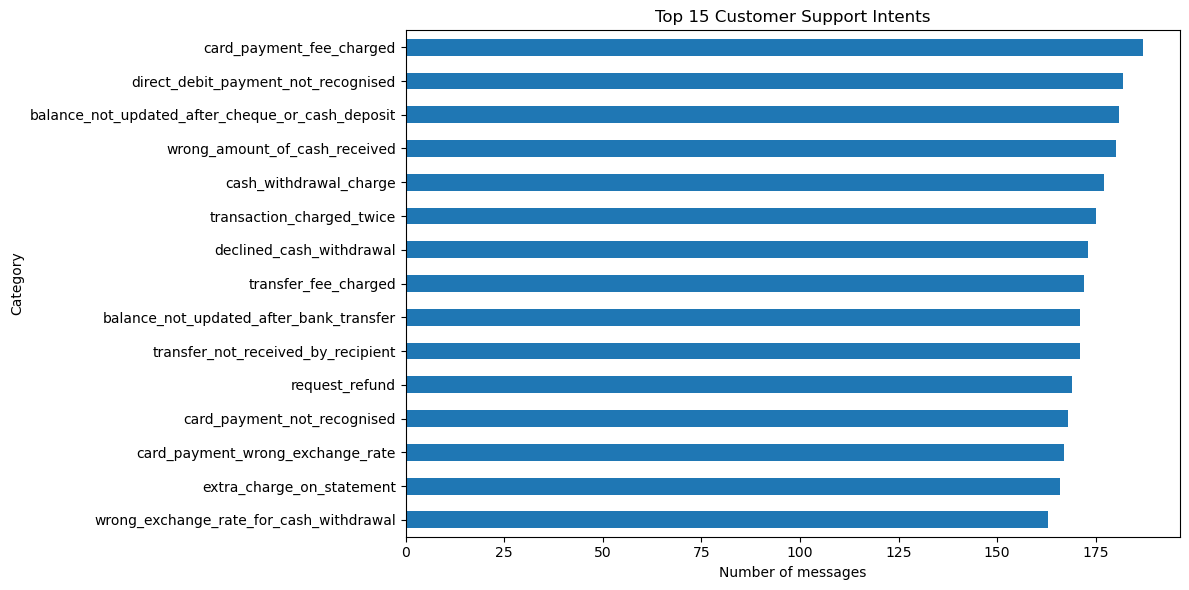

In [31]:
import matplotlib.pyplot as plt

category_counts = train_df["category"].value_counts()

print("Total categories:", len(category_counts))
print("\nTop 10 categories:")
print(category_counts.head(10))

print("\nBottom 10 categories:")
print(category_counts.tail(10))

# Visualize the 15 most common categories
plt.figure(figsize=(12, 6))

category_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Customer Support Intents")
plt.xlabel("Number of messages")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### 5 Initial Findings

The training dataset contains 10,003 customer messages across 77 intent categories, while the test dataset contains 3,080 messages.

No missing values were found during the initial inspection.

The category counts vary across the training set. `card_payment_fee_charged` is the most frequent category with 187 messages, while `contactless_not_working` is the least frequent with 35 messages.

This variation makes it important to evaluate the model using macro-F1 in addition to accuracy, so that performance across all intent categories is considered.

In [32]:
print("Duplicate training rows: ",train_df.duplicated().sum())
print("Duplicate test rows: ",test_df.duplicated().sum())
print("Repeating text messages:",train_df['text'].duplicated().sum())
train_texts = set(train_df['text'])
test_texts = set(test_df['text'])
print("Train_test Overlapping texts: ",train_texts.intersection(test_texts))

Duplicate training rows:  0
Duplicate test rows:  0
Repeating text messages: 0
Train_test Overlapping texts:  set()


## 6. Data Quality Checks

Missing values and duplicate records are checked before further analysis.

The initial inspection found no missing values in either column of the training dataset. The training and testing datasets also contain no duplicate rows or repeated messages within their respective files.

An overlap check was performed to identify identical message text appearing in both sets. No overlapping messages were found.

These checks provide confidence in the initial data quality, although they do not guarantee that every possible source of data leakage has been eliminated.

In [33]:
# Display 10 sample customer messages with their labels
for i in range(10):
    print("Text:", train_df.iloc[i]["text"])
    print("Category:", train_df.iloc[i]["category"])
    print("-" * 70)

Text: I am still waiting on my card?
Category: card_arrival
----------------------------------------------------------------------
Text: What can I do if my card still hasn't arrived after 2 weeks?
Category: card_arrival
----------------------------------------------------------------------
Text: I have been waiting over a week. Is the card still coming?
Category: card_arrival
----------------------------------------------------------------------
Text: Can I track my card while it is in the process of delivery?
Category: card_arrival
----------------------------------------------------------------------
Text: How do I know if I will get my card, or if it is lost?
Category: card_arrival
----------------------------------------------------------------------
Text: When did you send me my new card?
Category: card_arrival
----------------------------------------------------------------------
Text: Do you have info about the card on delivery?
Category: card_arrival
--------------------------

In [34]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_df["clean_text"] = train_df["text"].apply(clean_text)

print("Original text:")
print(train_df["text"].iloc[1])

print("\nCleaned text:")
print(train_df["clean_text"].iloc[1])

Original text:
What can I do if my card still hasn't arrived after 2 weeks?

Cleaned text:
what can i do if my card still hasn't arrived after 2 weeks?


In [35]:
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
text = train_df['text'].iloc[1].lower()
tokens =wordpunct_tokenize(text)
filtered_tokens = []
for i in tokens:
    if i.isalpha():
        if i not in stop_words:
            filtered_tokens.append(i)
print(filtered_tokens)

['card', 'still', 'arrived', 'weeks']


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 7. Text Preprocessing

Text preprocessing prepares customer messages for feature extraction and model training.

The following techniques will be explored:

- Lowercasing text to normalize capitalization.
- Tokenization to split messages into individual tokens.
- Stop-word removal to investigate the effect of common words.
- Lemmatization and stemming to examine word normalization.

These techniques will be evaluated rather than assumed to improve performance. Words such as negations may carry important information about customer intent, so removing stop words indiscriminately can reduce useful context.

The final preprocessing pipeline will be selected based on experimental results.

In [36]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
nltk.download("omw-1.4")

lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [37]:
lemmatized_tokens = []
for i in filtered_tokens:
    lemma=lemmatizer.lemmatize(i)
    lemmatized_tokens.append(lemma)
print("Before Lemmatization:",filtered_tokens)
print("After Lemmatization:",lemmatized_tokens)


Before Lemmatization: ['card', 'still', 'arrived', 'weeks']
After Lemmatization: ['card', 'still', 'arrived', 'week']


In [38]:
print("arrived:", lemmatizer.lemmatize("arrived", pos="v"))
print("running:", lemmatizer.lemmatize("running", pos="v"))
print("better:", lemmatizer.lemmatize("better", pos="a"))

arrived: arrive
running: run
better: good


### 8.1 Observations from Lemmatization

The WordNet Lemmatizer converts words into their base forms using a dictionary-based approach.

- By default, it treats words as nouns.
- Providing the correct part of speech can improve lemmatization.
- Lemmatization may reduce variations of words, but it does not always improve classification performance.
- In this project, its usefulness will be evaluated during model experimentation.

**Note:** The current examples demonstrate lemmatization on a single sample. A consistent preprocessing pipeline will be developed for the complete dataset later.

## 9. Stemming

Stemming is a text preprocessing technique that removes prefixes or suffixes from words to obtain their root form.

Unlike lemmatization, stemming does not always produce a valid dictionary word.

**Examples:**
- `playing` → `play`
- `studies` → `studi`
- `connected` → `connect`

In this project, stemming will be explored as another preprocessing technique for customer support ticket classification. Its results will later be compared with lemmatization.

In [39]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

In [40]:
stemmed_tokens = []

for i in filtered_tokens:
    stem = stemmer.stem(i)
    stemmed_tokens.append(stem)

print("Original tokens:", filtered_tokens)
print("Stemmed tokens:", stemmed_tokens)

Original tokens: ['card', 'still', 'arrived', 'weeks']
Stemmed tokens: ['card', 'still', 'arriv', 'week']


## 11. Stemming vs. Lemmatization

Stemming and lemmatization both reduce word variations, but they use different approaches.

| Aspect | Stemming | Lemmatization |
|---|---|---|
| Approach | Removes word endings using rules | Uses vocabulary and linguistic information |
| Output | May produce incomplete words | Generally produces meaningful base words |
| Example | `arrived` → `arriv` | `arrived` → `arrive` (when treated as a verb) |
| Speed | Generally faster | Can be slower |
| Linguistic accuracy | Less linguistically informed | More linguistically informed |

**Project decision:** We will evaluate different preprocessing approaches experimentally instead of assuming one is always better. For customer support messages, preserving meaningful words and negations can be especially important.

## 12. N-grams

N-grams are sequences of consecutive words or tokens in a text.

They help a model capture relationships between neighboring words rather than treating every word independently.

**Types of N-grams:**

- **Unigram:** A single word, e.g., `card`, `payment`
- **Bigram:** Two consecutive words, e.g., `card payment`
- **Trigram:** Three consecutive words, e.g., `card payment failed`

In customer support classification, phrases such as `cash withdrawal`, `direct debit`, and `cash withdrawal failed` may carry more meaning than individual words.

N-grams can be used with text vectorization methods such as CountVectorizer and TF-IDF.

In [41]:
from nltk.util import ngrams
from nltk.tokenize import wordpunct_tokenize

text = "my card payment failed"

tokens = wordpunct_tokenize(text.lower())

unigrams = list(ngrams(tokens, 1))
bigrams = list(ngrams(tokens, 2))
trigrams = list(ngrams(tokens, 3))

print("Unigrams:", unigrams)
print("Bigrams:", bigrams)
print("Trigrams:", trigrams)

Unigrams: [('my',), ('card',), ('payment',), ('failed',)]
Bigrams: [('my', 'card'), ('card', 'payment'), ('payment', 'failed')]
Trigrams: [('my', 'card', 'payment'), ('card', 'payment', 'failed')]


## 13. Bag of Words (BoW)

Bag of Words is a text representation technique that converts text into numerical features based on word occurrence or frequency.

A machine learning model cannot directly understand raw text, so we convert text into numbers.

BoW creates a vocabulary of unique words from the documents and represents each document using the counts of those words.

**Example documents:**

- Document 1: `I love banking`
- Document 2: `I love money`

Vocabulary: `I`, `love`, `banking`, `money`

| Document | I | love | banking | money |
|---|---:|---:|---:|---:|
| Document 1 | 1 | 1 | 1 | 0 |
| Document 2 | 1 | 1 | 0 | 1 |

**Limitation:** Basic BoW ignores word order and context. For example, `payment failed` and `failed payment` can have the same word counts.

In [42]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(ngram_range=(1, 1))

X_train_bow = bow_vectorizer.fit_transform(train_df["text"])
X_test_bow = bow_vectorizer.transform(test_df["text"])

print("Training matrix shape:", X_train_bow.shape)
print("Testing matrix shape:", X_test_bow.shape)

Training matrix shape: (10003, 2320)
Testing matrix shape: (3080, 2320)


## 14. TF-IDF (Term Frequency–Inverse Document Frequency)

TF-IDF is a text vectorization technique that converts text into numerical features while considering how important a word is within a document and across a collection of documents.

Unlike basic Bag of Words, which mainly counts word occurrences, TF-IDF reduces the relative importance of words that appear across many documents.

**Main components:**

- **Term Frequency (TF):** Measures how frequently a term appears in a document.
- **Inverse Document Frequency (IDF):** Reduces the weight of terms that appear in many documents.
- **TF-IDF:** Combines these components to assign a weight to each term.

**Example:** In customer support messages, a phrase such as `cash withdrawal` may help identify a particular intent. TF-IDF can represent the words numerically based on their distribution across messages.

**Limitation:** TF-IDF does not understand meaning or context like a human. It relies on statistical patterns in the text.

In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer
doc = ["I love banking","I love money","banking helps people"]
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(doc)
print("Vocabulary:", tfidf_vectorizer.get_feature_names_out())
print("\nTF-IDF Matrix:\n", X_tfidf.toarray().round(2))


Vocabulary: ['banking' 'helps' 'love' 'money' 'people']

TF-IDF Matrix:
 [[0.71 0.   0.71 0.   0.  ]
 [0.   0.   0.61 0.8  0.  ]
 [0.47 0.62 0.   0.   0.62]]


In [44]:
print("Number of documents:", len(doc))
print("Documents:", doc)
print("TF-IDF matrix shape:", X_tfidf.shape)

Number of documents: 3
Documents: ['I love banking', 'I love money', 'banking helps people']
TF-IDF matrix shape: (3, 5)


## 15. Word Embeddings

Word embeddings are a text representation technique that converts words into dense numerical vectors. These vectors can capture semantic relationships between words based on patterns learned from text.

Machine learning models cannot directly understand words, so text must be represented numerically.

Unlike Bag of Words and TF-IDF, which create features based mainly on word occurrence and frequency, word embeddings can learn relationships between words.

**Example:**

Words such as `king` and `queen` may have related vector representations because they share certain semantic properties.

Similarly, in banking-related text, words such as `payment`, `transaction`, and `transfer` may have related representations if the training data captures those relationships.

**Advantages:**
- Can capture semantic similarities between words.
- Represent words as dense vectors.
- Can be useful for NLP tasks such as text classification and sentiment analysis.

**Limitations:**
- Quality depends on the training data and embedding method.
- Traditional word embeddings usually assign one vector to each word, even when the word has different meanings in different contexts.

**Common word embedding techniques:**
1. Word2Vec
2. GloVe
3. FastText

These techniques differ in how they learn vector representations from text.

In [45]:
import numpy as np

word_vectors = {
    "payment": np.array([0.8, 0.6, 0.2]),
    "transfer": np.array([0.7, 0.5, 0.3]),
    "banana": np.array([0.1, 0.9, 0.8])
}

print("Payment vector:", word_vectors["payment"])
print("Transfer vector:", word_vectors["transfer"])
print("Banana vector:", word_vectors["banana"])

Payment vector: [0.8 0.6 0.2]
Transfer vector: [0.7 0.5 0.3]
Banana vector: [0.1 0.9 0.8]


## 16. Word Similarity

Word similarity measures how similar two word vectors are in the vector space.

A common method is **Cosine Similarity**, which measures the cosine of the angle between two vectors.

- A value close to `1` indicates that the vectors point in a similar direction.
- A value close to `0` indicates little directional similarity.
- A value close to `-1` indicates opposite directions.

Cosine similarity is commonly used to compare word embeddings and other numerical text representations.

**Note:** Similarity scores are meaningful only in relation to the vectors being compared. Arbitrary vectors do not automatically represent real linguistic similarity.

In [46]:
from sklearn.metrics.pairwise import cosine_similarity

payment = word_vectors["payment"].reshape(1, -1)
transfer = word_vectors["transfer"].reshape(1, -1)
banana = word_vectors["banana"].reshape(1, -1)

print("Payment vs Transfer:",
      cosine_similarity(payment, transfer)[0][0].round(3))

print("Payment vs Banana:",
      cosine_similarity(payment, banana)[0][0].round(3))

Payment vs Transfer: 0.99
Payment vs Banana: 0.633


## 17. Word2Vec

Word2Vec is a word embedding technique that learns dense numerical representations of words from their surrounding context in a text corpus.

Words that appear in similar contexts can develop similar vector representations.

**Word2Vec has two main architectures:**

1. **CBOW (Continuous Bag of Words):** Predicts a target word using its surrounding context words.
2. **Skip-gram:** Predicts surrounding context words using a target word.

**Example:**

In the sentence `I need help with my bank transfer`, Word2Vec learns from relationships between words and their surrounding context.

**Applications:**
- Finding similar words
- Text classification
- Recommendation systems
- Other NLP tasks

**Limitation:** Word2Vec generally learns one vector per word, so it does not fully distinguish different meanings of the same word in different contexts.

In [47]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [48]:
from gensim.models import Word2Vec

sentences = [
    ["bank", "transfer", "payment", "money"],
    ["payment", "card", "bank", "account"],
    ["money", "transfer", "bank", "account"],
    ["card", "payment", "transaction", "bank"],
    ["transfer", "money", "transaction", "payment"]
]

In [49]:
model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    sg=1,
    seed=42,
    epochs=100
)

In [50]:
print("Vector for 'payment':")
print(model.wv["payment"])

print("\nVector shape:")
print(model.wv["payment"].shape)

Vector for 'payment':
[-1.64861325e-02  1.10128848e-02  6.09562034e-03 -2.42693676e-03
 -2.66251760e-03  1.41910920e-02 -1.66173410e-02  7.86751229e-03
 -1.20465392e-02 -1.62432734e-02  1.22995651e-03  1.91536397e-02
  9.36756097e-03  1.05779162e-02  8.76563136e-03  1.14966985e-02
  5.59336622e-04 -1.50189791e-02  1.36246225e-02 -1.94717885e-03
 -7.78043322e-05 -5.42327901e-03 -1.27305845e-02  1.71926189e-02
  1.14495000e-02  5.69782313e-03 -3.94645007e-03  1.28531735e-02
  1.75300625e-03 -2.33144546e-03 -1.89766148e-03 -1.09756831e-02
 -1.64941791e-02  2.35180045e-03  1.55783258e-02 -1.73347145e-02
  1.43187623e-02  1.30696660e-02 -9.00505017e-03  5.40680019e-03
 -1.33896219e-02  1.03577366e-02  8.16143211e-03 -5.88102266e-03
 -1.71280894e-02  1.87352486e-02 -2.08400516e-03  1.58201791e-02
  7.09910877e-03  1.09657608e-02]

Vector shape:
(50,)


In [51]:
similar_words = model.wv.most_similar('payment',topn=3)
print("Words similar to 'payment':")
for word,score in similar_words:
    print(word,score)

Words similar to 'payment':
card 0.05080348998308182
money -0.01314780954271555
transaction -0.023339446634054184


### 18.1 Observations from Word2Vec

The Word2Vec model was trained on a small, manually prepared corpus using the Skip-gram architecture.

- Each word was represented by a 50-dimensional vector.
- The `most_similar()` method ranked words using cosine similarity.
- The results were weak because the training corpus was too small to learn reliable semantic relationships.

**Conclusion:** Word2Vec demonstrates how dense word representations can be learned from text. 

## 19. Part-of-Speech (POS) Tagging

Part-of-Speech tagging is an NLP technique that assigns a grammatical category to each word in a sentence.

Common categories include:

- **Noun (NN):** A person, place, thing, or concept.
- **Verb (VB):** An action or state.
- **Adjective (JJ):** Describes a noun.
- **Adverb (RB):** Modifies a verb, adjective, or another adverb.
- **Pronoun (PRP):** Replaces a noun.

**Example:**

Sentence: `The customer transferred money quickly.`

- `customer` → Noun
- `transferred` → Verb
- `money` → Noun
- `quickly` → Adverb

POS tagging can help identify the grammatical role of a word. It can also improve lemmatization when the correct part of speech is supplied.

In this project, POS tagging is a concept to understand; we will decide later whether it is useful in our final preprocessing pipeline.

In [52]:
import nltk

nltk.download("averaged_perceptron_tagger_eng")

sentence = "The customer transferred money quickly"

tokens = nltk.word_tokenize(sentence)

pos_tags = nltk.pos_tag(tokens)

print(pos_tags)

[('The', 'DT'), ('customer', 'NN'), ('transferred', 'VBD'), ('money', 'NN'), ('quickly', 'RB')]


[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [53]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [54]:
sentence = "The customer transferred money quickly"

tokens = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(tokens)

print(pos_tags)

[('The', 'DT'), ('customer', 'NN'), ('transferred', 'VBD'), ('money', 'NN'), ('quickly', 'RB')]


In [55]:
word = "transferred"

print("Without POS:", lemmatizer.lemmatize(word))
print("With verb POS:", lemmatizer.lemmatize(word, pos="v"))

Without POS: transferred
With verb POS: transfer


### Observations: POS-Based Lemmatization

- Default lemmatization may treat a word as a noun, so `transferred` remains unchanged.
- When we specify the verb POS (`pos="v"`), `transferred` becomes `transfer`.
- POS tagging identifies the grammatical role of each word, which can improve lemmatization.
- POS-based lemmatization is more context-aware, but it requires additional processing.

**Conclusion:** POS-based lemmatization can help normalize words more accurately, although we should compare preprocessing methods on our actual dataset before choosing one for the final model.

## Named Entity Recognition (NER)

Named Entity Recognition (NER) is an NLP technique used to identify and classify named entities in text.

Common entity types include:

- **PERSON:** Names of people, such as Rahul.
- **ORGANIZATION:** Names of companies, such as Google.
- **LOCATION:** Places, such as Delhi.
- **DATE:** Dates or days, such as Monday.
- **MONEY:** Monetary values, such as ₹5,000.

**Example:**

"I transferred ₹5,000 to Rahul on Monday."

NER may identify `₹5,000` as MONEY, `Rahul` as PERSON, and `Monday` as DATE.

### NER vs POS Tagging

- **POS Tagging:** Identifies the grammatical role of each word, such as noun, verb, or adjective.
- **NER:** Identifies entities such as people, organizations, and locations.

### Applications in Our Project

In our Smart Customer Support Ticket Intelligence System, NER could help identify useful information such as banks, monetary amounts, dates, or transaction references mentioned in customer messages.

However, NER is not required for classifying tickets into BANKING77 categories. We will evaluate its usefulness before adding it to our final pipeline.

In [57]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("maxent_ne_chunker_tab")
nltk.download("words")


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package maxent_ne_chunker_tab is already up-to-date!
[nltk_data] Downloading package words to
[nltk_data]     C:\Users\krish\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!


True

In [58]:
sentence = "Google hired Rahul in Delhi on Monday"

print(sentence)

Google hired Rahul in Delhi on Monday


In [59]:
tokens = nltk.word_tokenize(sentence)

print("Tokens:")
print(tokens)

pos_tags = nltk.pos_tag(tokens)

print("\nPOS Tags:")
print(pos_tags)

Tokens:
['Google', 'hired', 'Rahul', 'in', 'Delhi', 'on', 'Monday']

POS Tags:
[('Google', 'NNP'), ('hired', 'VBD'), ('Rahul', 'NNP'), ('in', 'IN'), ('Delhi', 'NNP'), ('on', 'IN'), ('Monday', 'NNP')]


In [60]:
named_entities = nltk.ne_chunk(pos_tags)

print(named_entities)

(S
  (PERSON Google/NNP)
  hired/VBD
  (PERSON Rahul/NNP)
  in/IN
  (GPE Delhi/NNP)
  on/IN
  Monday/NNP)


In [61]:
entities = []

for chunk in named_entities:
    if hasattr(chunk, "label"):
        entity_name = " ".join(word for word, tag in chunk.leaves())
        entity_label = chunk.label()
        entities.append((entity_name, entity_label))

print("Extracted Named Entities:")

for entity, label in entities:
    print(f"{entity} -> {label}")

Extracted Named Entities:
Google -> PERSON
Rahul -> PERSON
Delhi -> GPE


## Practical Implementation 

We have explored the core NLP concepts using small examples. Now, we will apply relevant techniques to our actual BANKING77 dataset.

We will first inspect the existing training and testing DataFrames, then build and compare text representations and classification models.

We will keep the provided test set separate and use training data for model development and validation.

In [62]:
print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)

print("\nTraining Columns:")
print(train_df.columns.tolist())

print("\nTesting Columns:")
print(test_df.columns.tolist())

print("\nTraining Data Sample:")
display(train_df.head())

Training Data Shape: (10003, 3)
Testing Data Shape: (3080, 2)

Training Columns:
['text', 'category', 'clean_text']

Testing Columns:
['text', 'category']

Training Data Sample:


,text,category,clean_text
0,I am still waiting on my card?,card_arrival,i am still waiting on my card?
1,What can I do if my card still hasn't arrived ...,card_arrival,what can i do if my card still hasn't arrived ...
2,I have been waiting over a week. Is the card s...,card_arrival,i have been waiting over a week. is the card s...
3,Can I track my card while it is in the process...,card_arrival,can i track my card while it is in the process...
4,"How do I know if I will get my card, or if it ...",card_arrival,"how do i know if i will get my card, or if it ..."


In [63]:
# Apply the existing cleaning function to the test dataset

test_df["clean_text"] = test_df["text"].apply(clean_text)

print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)

print("\nTesting Data Sample:")
display(test_df.head())

Training Data Shape: (10003, 3)
Testing Data Shape: (3080, 3)

Testing Data Sample:


,text,category,clean_text
0,How do I locate my card?,card_arrival,how do i locate my card?
1,"I still have not received my new card, I order...",card_arrival,"i still have not received my new card, i order..."
2,I ordered a card but it has not arrived. Help ...,card_arrival,i ordered a card but it has not arrived. help ...
3,Is there a way to know when my card will arrive?,card_arrival,is there a way to know when my card will arrive?
4,My card has not arrived yet.,card_arrival,my card has not arrived yet.


In [64]:
# Check whether BoW and TF-IDF feature matrices already exist

print("BoW training matrix exists:", "X_train_bow" in globals())
print("BoW testing matrix exists:", "X_test_bow" in globals())

print("TF-IDF training matrix exists:", "X_train_tfidf" in globals())
print("TF-IDF testing matrix exists:", "X_test_tfidf" in globals())

BoW training matrix exists: True
BoW testing matrix exists: True
TF-IDF training matrix exists: False
TF-IDF testing matrix exists: False


## TF-IDF Vectorization 

TF-IDF (Term Frequency–Inverse Document Frequency) converts text into numerical features based on how important a word is in a document compared with the entire collection of documents.

Unlike Bag of Words, which primarily represents word counts, TF-IDF reduces the weight of words that appear frequently across many documents and gives more importance to words that are relatively distinctive.

We will apply TF-IDF to the `clean_text` column of our  training and testing datasets. The vectorizer will be fitted only on training text to avoid data leakage, and the same fitted vectorizer will transform the testing text.

In [65]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer()

# Fit on training text and transform it
X_train_tfidf = tfidf_vectorizer.fit_transform(
    train_df["clean_text"]
)

# Transform testing text using the same vectorizer
X_test_tfidf = tfidf_vectorizer.transform(
    test_df["clean_text"]
)

print("TF-IDF Training Matrix Shape:", X_train_tfidf.shape)
print("TF-IDF Testing Matrix Shape:", X_test_tfidf.shape)
print("Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))

TF-IDF Training Matrix Shape: (10003, 2320)
TF-IDF Testing Matrix Shape: (3080, 2320)
Vocabulary Size: 2320


In [66]:
# Display the first 20 words in the learned vocabulary
feature_names = tfidf_vectorizer.get_feature_names_out()

print("First 20 TF-IDF Features:")
print(feature_names[:20])

# Display TF-IDF values for the first training ticket
first_ticket_tfidf = X_train_tfidf[0].toarray()[0]

print("\nOriginal Ticket:")
print(train_df["text"].iloc[0])

print("\nNon-zero TF-IDF Features:")

nonzero_indices = first_ticket_tfidf.nonzero()[0]

for index in nonzero_indices:
    print(feature_names[index], ":", round(first_ticket_tfidf[index], 4))

First 20 TF-IDF Features:
['00' '000' '10' '100' '13' '16' '18' '1818' '1l' '20' '200' '2018' '30'
 '3d' '40' '45' '50' '500' '5x' '60']

Original Ticket:
I am still waiting on my card?

Non-zero TF-IDF Features:
am : 0.4312
card : 0.2479
my : 0.1775
on : 0.3661
still : 0.459
waiting : 0.6135


## Preparing Target Labels

The `category` column contains the correct category for each customer support ticket. These categories are the target labels that our machine learning models will learn to predict.

We will use the training dataset's categories as `y_train` and the testing dataset's categories as `y_test`.

In [68]:
# Extract target labels
y_train = train_df["category"]
y_test = test_df["category"]

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nFirst 5 Training Labels:")
print(y_train.head())

Training Labels Shape: (10003,)
Testing Labels Shape: (3080,)

First 5 Training Labels:
0    card_arrival
1    card_arrival
2    card_arrival
3    card_arrival
4    card_arrival
Name: category, dtype: object


## Model 1: Multinomial Naive Bayes using TF-IDF

Multinomial Naive Bayes is a probabilistic machine learning algorithm commonly used for text classification.

In this step, we will train the model using TF-IDF features and the corresponding training labels. We will then predict the categories of the test tickets and evaluate the model using accuracy and a classification report.

This model will serve as our baseline for comparison with other classifiers.

In [69]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Initialize the model
nb_model = MultinomialNB()

# Train the model using TF-IDF features
nb_model.fit(X_train_tfidf, y_train)

# Predict categories for test tickets
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Multinomial Naive Bayes — TF-IDF")
print("Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

Multinomial Naive Bayes — TF-IDF
Accuracy: 78.86 %

Classification Report:
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.92      0.90      0.91        40
                                activate_my_card       0.63      0.95      0.76        40
                                       age_limit       1.00      0.95      0.97        40
                         apple_pay_or_google_pay       0.82      1.00      0.90        40
                                     atm_support       0.89      0.60      0.72        40
                                automatic_top_up       0.92      0.90      0.91        40
         balance_not_updated_after_bank_transfer       0.60      0.78      0.67        40
balance_not_updated_after_cheque_or_cash_deposit       0.69      0.93      0.79        40
                         beneficiary_not_allowed       0.81      0.88      0.84        40
                        

## Model 2: Multinomial Naive Bayes using Bag of Words

In this step, we will train Multinomial Naive Bayes using Bag of Words (BoW) features.

We will compare its performance with the TF-IDF-based model to understand how different text representations affect customer support ticket classification.

Both models will use the same training and testing datasets.

In [70]:
# Initialize the model
nb_bow_model = MultinomialNB()

# Train using BoW features
nb_bow_model.fit(X_train_bow, y_train)

# Predict test categories
y_pred_nb_bow = nb_bow_model.predict(X_test_bow)

# Evaluate accuracy
nb_bow_accuracy = accuracy_score(y_test, y_pred_nb_bow)

print("Multinomial Naive Bayes — BoW")
print("Accuracy:", round(nb_bow_accuracy * 100, 2), "%")

print("\nComparison with TF-IDF:")
print("BoW Accuracy:", round(nb_bow_accuracy * 100, 2), "%")
print("TF-IDF Accuracy:", round(nb_accuracy * 100, 2), "%")

Multinomial Naive Bayes — BoW
Accuracy: 79.58 %

Comparison with TF-IDF:
BoW Accuracy: 79.58 %
TF-IDF Accuracy: 78.86 %


### Comparison: BoW vs TF-IDF with Multinomial Naive Bayes

The Multinomial Naive Bayes model achieved 79.58% accuracy using Bag of Words and 78.86% using TF-IDF.

BoW performed slightly better, with an improvement of 0.72 percentage points in accuracy. However, accuracy alone is insufficient to select the final model, so we will also compare macro F1-score and other evaluation metrics across multiple classifiers.

In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Initialize Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

# Train the model using TF-IDF
lr_model.fit(X_train_tfidf, y_train)

# Predict test categories
y_pred_lr = lr_model.predict(X_test_tfidf)

# Evaluate the model
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_macro_f1 = f1_score(y_test, y_pred_lr, average="macro")

print("Logistic Regression — TF-IDF")
print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Macro F1-score:", round(lr_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Logistic Regression — TF-IDF
Accuracy: 87.69 %
Macro F1-score: 0.8769

Classification Report:
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.85      0.88      0.86        40
                                activate_my_card       1.00      0.95      0.97        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       0.98      1.00      0.99        40
                                     atm_support       0.97      0.90      0.94        40
                                automatic_top_up       1.00      0.90      0.95        40
         balance_not_updated_after_bank_transfer       0.63      0.78      0.70        40
balance_not_updated_after_cheque_or_cash_deposit       0.84      0.95      0.89        40
                         beneficiary_not_allowed       0.94      0.85      0.89        40
     

### Logistic Regression Results — TF-IDF

Logistic Regression achieved 87.69% accuracy and a macro F1-score of 0.8769 on the test dataset.

It outperformed both Multinomial Naive Bayes baselines evaluated so far. This suggests that Logistic Regression is better able to distinguish between the customer support ticket categories using TF-IDF features.

Further experiments with BoW and other classifiers are required before selecting the final model.

In [72]:
# Initialize Logistic Regression
lr_bow_model = LogisticRegression(max_iter=1000)

# Train using BoW features
lr_bow_model.fit(X_train_bow, y_train)

# Predict test categories
y_pred_lr_bow = lr_bow_model.predict(X_test_bow)

# Evaluate
lr_bow_accuracy = accuracy_score(y_test, y_pred_lr_bow)
lr_bow_macro_f1 = f1_score(y_test, y_pred_lr_bow, average="macro")

print("Logistic Regression — BoW")
print("Accuracy:", round(lr_bow_accuracy * 100, 2), "%")
print("Macro F1-score:", round(lr_bow_macro_f1, 4))

print("\nComparison:")
print(f"BoW Accuracy: {lr_bow_accuracy * 100:.2f}%")
print(f"TF-IDF Accuracy: {lr_accuracy * 100:.2f}%")

Logistic Regression — BoW
Accuracy: 88.93 %
Macro F1-score: 0.8894

Comparison:
BoW Accuracy: 88.93%
TF-IDF Accuracy: 87.69%


### Comparison: Logistic Regression with BoW vs TF-IDF

Logistic Regression achieved 88.93% accuracy and a macro F1-score of 0.8894 using Bag of Words features. With TF-IDF, it achieved 87.69% accuracy and a macro F1-score of 0.8769.

In this experiment, BoW outperformed TF-IDF for Logistic Regression. We will evaluate additional classifiers before selecting the final model.

In [73]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

# Initialize Linear SVM
svm_bow_model = LinearSVC(random_state=42)

# Train using BoW features
svm_bow_model.fit(X_train_bow, y_train)

# Predict test categories
y_pred_svm_bow = svm_bow_model.predict(X_test_bow)

# Evaluate
svm_bow_accuracy = accuracy_score(y_test, y_pred_svm_bow)
svm_bow_macro_f1 = f1_score(
    y_test, y_pred_svm_bow, average="macro"
)

print("Linear SVM — BoW")
print("Accuracy:", round(svm_bow_accuracy * 100, 2), "%")
print("Macro F1-score:", round(svm_bow_macro_f1, 4))

Linear SVM — BoW
Accuracy: 88.64 %
Macro F1-score: 0.8863


### Linear SVM Results — BoW

The Linear Support Vector Machine achieved 88.64% accuracy and a macro F1-score of 0.8863 using Bag of Words features.

Its performance was close to Logistic Regression with BoW, which achieved 88.93% accuracy and a macro F1-score of 0.8894. We will now evaluate Linear SVM using TF-IDF features for a fair comparison.

In [74]:
# Initialize Linear SVM
svm_tfidf_model = LinearSVC(random_state=42)

# Train using TF-IDF features
svm_tfidf_model.fit(X_train_tfidf, y_train)

# Predict test categories
y_pred_svm_tfidf = svm_tfidf_model.predict(X_test_tfidf)

# Evaluate
svm_tfidf_accuracy = accuracy_score(y_test, y_pred_svm_tfidf)
svm_tfidf_macro_f1 = f1_score(
    y_test, y_pred_svm_tfidf, average="macro"
)

print("Linear SVM — TF-IDF")
print("Accuracy:", round(svm_tfidf_accuracy * 100, 2), "%")
print("Macro F1-score:", round(svm_tfidf_macro_f1, 4))

Linear SVM — TF-IDF
Accuracy: 89.51 %
Macro F1-score: 0.895


### Linear SVM Results — TF-IDF

Linear SVM achieved 89.51% accuracy and a macro F1-score of 0.8950 using TF-IDF features.

It outperformed the other models evaluated so far. Compared with Linear SVM using BoW, TF-IDF improved accuracy by 0.87 percentage points.

Linear SVM with TF-IDF is currently the leading candidate, but we will examine additional evaluation metrics before selecting the final model.

In [75]:
import pandas as pd

model_results = pd.DataFrame([
    {
        "Model": "Multinomial Naive Bayes",
        "Features": "BoW",
        "Accuracy": nb_bow_accuracy,
        "Macro F1": f1_score(y_test, y_pred_nb_bow, average="macro")
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Features": "TF-IDF",
        "Accuracy": nb_accuracy,
        "Macro F1": f1_score(y_test, y_pred_nb, average="macro")
    },
    {
        "Model": "Logistic Regression",
        "Features": "TF-IDF",
        "Accuracy": lr_accuracy,
        "Macro F1": lr_macro_f1
    },
    {
        "Model": "Logistic Regression",
        "Features": "BoW",
        "Accuracy": lr_bow_accuracy,
        "Macro F1": lr_bow_macro_f1
    },
    {
        "Model": "Linear SVM",
        "Features": "BoW",
        "Accuracy": svm_bow_accuracy,
        "Macro F1": svm_bow_macro_f1
    },
    {
        "Model": "Linear SVM",
        "Features": "TF-IDF",
        "Accuracy": svm_tfidf_accuracy,
        "Macro F1": svm_tfidf_macro_f1
    }
])

model_results = model_results.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

model_results["Accuracy"] = (model_results["Accuracy"] * 100).round(2)
model_results["Macro F1"] = model_results["Macro F1"].round(4)

model_results


,Model,Features,Accuracy,Macro F1
0,Linear SVM,TF-IDF,89.51,0.8950
1,Logistic Regression,BoW,88.93,0.8894
2,Linear SVM,BoW,88.64,0.8863
3,Logistic Regression,TF-IDF,87.69,0.8769
4,Multinomial Naive Bayes,BoW,79.58,0.7884
5,Multinomial Naive Bayes,TF-IDF,78.86,0.7731


In [76]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

# TF-IDF with unigrams and bigrams
tfidf_ngram = TfidfVectorizer(ngram_range=(1, 2))

X_train_tfidf_ngram = tfidf_ngram.fit_transform(
    train_df["clean_text"]
)

X_test_tfidf_ngram = tfidf_ngram.transform(
    test_df["clean_text"]
)

print("Training matrix:", X_train_tfidf_ngram.shape)
print("Testing matrix:", X_test_tfidf_ngram.shape)

# Train Linear SVM
svm_ngram_model = LinearSVC(random_state=42)

svm_ngram_model.fit(X_train_tfidf_ngram, y_train)

# Evaluate
y_pred_svm_ngram = svm_ngram_model.predict(
    X_test_tfidf_ngram
)

ngram_accuracy = accuracy_score(y_test, y_pred_svm_ngram)
ngram_macro_f1 = f1_score(
    y_test, y_pred_svm_ngram, average="macro"
)

print("\nLinear SVM — TF-IDF Unigrams + Bigrams")
print("Accuracy:", round(ngram_accuracy * 100, 2), "%")
print("Macro F1-score:", round(ngram_macro_f1, 4))

Training matrix: (10003, 23608)
Testing matrix: (3080, 23608)

Linear SVM — TF-IDF Unigrams + Bigrams
Accuracy: 89.32 %
Macro F1-score: 0.8934


### N-gram Experiment Results

Linear SVM with unigram TF-IDF achieved 89.51% accuracy and a macro F1-score of 0.8950. Adding bigrams increased the feature count from 2,320 to 23,608, but accuracy decreased slightly to 89.32%, with a macro F1-score of 0.8934.

This experiment suggests that adding bigram features did not improve performance under the current settings. The unigram TF-IDF model remains the leading candidate.


## Validation-Based Model Selection

We have compared multiple models using the provided test dataset. To follow a more reliable evaluation process, we will now split the training data into training and validation sets.

We will train models on the training portion and compare their performance on the validation portion. The provided test dataset will be reserved for final evaluation after selecting the model and configuration.

In [77]:
from sklearn.model_selection import train_test_split

# Split training data into training and validation sets
X_train_part, X_val, y_train_part, y_val = train_test_split(
    train_df["clean_text"],
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_part))
print("Validation samples:", len(X_val))
print("Training categories:", y_train_part.nunique())
print("Validation categories:", y_val.nunique())

Training samples: 8002
Validation samples: 2001
Training categories: 77
Validation categories: 77


## TF-IDF Feature Extraction for Validation

We will convert the training and validation text into numerical features using TF-IDF.

The vectorizer will be fitted only on the training portion. The same fitted vectorizer will then transform the validation text, ensuring that information from the validation vocabulary is not used during fitting.

We will use unigram features, since our earlier experiments showed that adding bigrams did not improve the Linear SVM baseline.

In [78]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf_val = TfidfVectorizer()

# Fit only on the training portion
X_train_tfidf_val = tfidf_val.fit_transform(X_train_part)

# Transform validation data using the same vectorizer
X_val_tfidf = tfidf_val.transform(X_val)

print("Training TF-IDF shape:", X_train_tfidf_val.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Vocabulary size:", len(tfidf_val.vocabulary_))

Training TF-IDF shape: (8002, 2127)
Validation TF-IDF shape: (2001, 2127)
Vocabulary size: 2127


## Training and Evaluating the Linear SVM Model

We will train a Linear Support Vector Classifier (Linear SVM) using the training TF-IDF features and evaluate it on the validation set.

We will measure **accuracy** and **macro F1-score**. Accuracy measures overall correct predictions, while macro F1 calculates the F1-score for each category and gives every category equal weight.

These metrics will help us assess performance across all 77 customer support ticket categories.

In [79]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Initialize and train the model
svm_val_model = LinearSVC(random_state=42)
svm_val_model.fit(X_train_tfidf_val, y_train_part)

# Predict validation labels
y_val_pred = svm_val_model.predict(X_val_tfidf)

# Evaluate the model
val_accuracy = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro F1-score: {val_macro_f1:.4f}")

Validation Accuracy: 0.8836
Validation Macro F1-score: 0.8834


## Hyperparameter Tuning of Linear SVM

The baseline Linear SVM provides a strong starting point. We will now experiment with different values of the regularization parameter `C`.

The parameter `C` controls the trade-off between model complexity and classification errors. A smaller value applies stronger regularization, while a larger value allows the model to fit the training data more closely.

We will compare the models using the validation macro F1-score and select the configuration that performs best across the 77 categories.

In [80]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

C_values = [0.1, 0.5, 1, 2, 5]

tuning_results = []

for c in C_values:
    model = LinearSVC(C=c, random_state=42)
    model.fit(X_train_tfidf_val, y_train_part)

    val_predictions = model.predict(X_val_tfidf)

    accuracy = accuracy_score(y_val, val_predictions)
    macro_f1 = f1_score(y_val, val_predictions, average="macro")

    tuning_results.append({
        "C": c,
        "Validation Accuracy": accuracy,
        "Validation Macro F1": macro_f1
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df.sort_values(
    by="Validation Macro F1",
    ascending=False
).reset_index(drop=True)

,C,Validation Accuracy,Validation Macro F1
0,0.5,0.884558,0.883605
1,1.0,0.883558,0.883441
2,2.0,0.881559,0.880310
3,5.0,0.875062,0.872962
4,0.1,0.861069,0.853953


## Selecting the Best Linear SVM Configuration

We compared five values of the regularization parameter `C` using the validation set.

The best configuration was `C = 0.5`, which achieved a validation accuracy of approximately 88.46% and a macro F1-score of 0.8836.

We will select this configuration for further evaluation. The improvement over the default configuration is small, so we will report the results honestly rather than claim a major performance gain.

In [81]:
best_svm_model = LinearSVC(C=0.5, random_state=42)

best_svm_model.fit(X_train_tfidf_val, y_train_part)

best_val_predictions = best_svm_model.predict(X_val_tfidf)

print(
    "Best Validation Accuracy:",
    round(accuracy_score(y_val, best_val_predictions) * 100, 2),
    "%"
)

print(
    "Best Validation Macro F1:",
    round(f1_score(y_val, best_val_predictions, average="macro"), 4)
)

Best Validation Accuracy: 88.46 %
Best Validation Macro F1: 0.8836


## Error Analysis of the Best Linear SVM Model

Error analysis helps us understand the limitations of our classifier by examining incorrectly predicted customer support tickets.

We will compare the actual categories with the predicted categories on the validation set. This will help us identify confusing categories and understand where the model struggles.

We will perform this analysis using validation predictions, keeping the provided test dataset out of this step.

In [82]:
error_analysis = pd.DataFrame({
    "Ticket": X_val.reset_index(drop=True),
    "Actual Category": y_val.reset_index(drop=True),
    "Predicted Category": best_val_predictions
})

misclassified = error_analysis[
    error_analysis["Actual Category"] != error_analysis["Predicted Category"]
].copy()

print("Total validation tickets:", len(error_analysis))
print("Misclassified tickets:", len(misclassified))
print(
    "Validation error rate:",
    round(len(misclassified) / len(error_analysis) * 100, 2),
    "%"
)

misclassified.head(10)

Total validation tickets: 2001
Misclassified tickets: 231
Validation error rate: 11.54 %


,Ticket,Actual Category,Predicted Category
1,what are the fees imposed when i make a transa...,card_payment_fee_charged,transfer_not_received_by_recipient
7,my withdrawals were going smooth until i got d...,declined_cash_withdrawal,card_not_working
24,why is there an uknown charge showing on my ac...,card_payment_not_recognised,extra_charge_on_statement
30,what's up with the extra fee i got?,cash_withdrawal_charge,card_payment_fee_charged
37,why has my payment not transferred?,failed_transfer,balance_not_updated_after_bank_transfer
42,i need help verifying my identity.,unable_to_verify_identity,why_verify_identity
64,i returned an item but don't see it on my acco...,Refund_not_showing_up,reverted_card_payment?
66,what is this extra charge with my purchase?,card_payment_fee_charged,extra_charge_on_statement
68,my balance is not what i thought it was follow...,pending_cash_withdrawal,cash_withdrawal_not_recognised
69,what payment methods are used to top up?,supported_cards_and_currencies,top_up_by_cash_or_cheque


In [83]:
# Count the most frequent actual-predicted category pairs
confusion_pairs = (
    misclassified.groupby(
        ["Actual Category", "Predicted Category"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("Most frequent confusion pairs:")
display(confusion_pairs.head(15))

print("\nCategories with the most misclassifications:")
display(
    misclassified["Actual Category"]
    .value_counts()
    .head(10)
    .rename_axis("Actual Category")
    .reset_index(name="Misclassified Tickets")
)

Most frequent confusion pairs:


,Actual Category,Predicted Category,Count
72,direct_debit_payment_not_recognised,card_payment_not_recognised,6
171,why_verify_identity,verify_my_identity,6
138,top_up_failed,pending_top_up,4
86,fiat_currency_support,supported_cards_and_currencies,4
104,pending_cash_withdrawal,declined_cash_withdrawal,4
170,why_verify_identity,unable_to_verify_identity,3
11,balance_not_updated_after_bank_transfer,pending_transfer,3
40,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,3
51,change_pin,get_physical_card,3
109,pending_top_up,top_up_failed,3



Categories with the most misclassifications:


,Actual Category,Misclassified Tickets
0,top_up_failed,10
1,why_verify_identity,9
2,pending_cash_withdrawal,8
3,direct_debit_payment_not_recognised,8
4,pending_transfer,8
5,balance_not_updated_after_bank_transfer,8
6,pending_top_up,8
7,declined_card_payment,6
8,cash_withdrawal_charge,6
9,beneficiary_not_allowed,6


In [84]:
from sklearn.metrics import classification_report

category_report = classification_report(
    y_val,
    best_val_predictions,
    output_dict=True,
    zero_division=0
)

category_performance = (
    pd.DataFrame(category_report)
    .T
    .iloc[:-3]
    .reset_index()
    .rename(columns={"index": "Category"})
)

category_performance = category_performance.sort_values(
    by="f1-score",
    ascending=True
)

display(
    category_performance[
        ["Category", "precision", "recall", "f1-score", "support"]
    ].head(15).round(3)
)

,Category,precision,recall,f1-score,support
59,top_up_failed,0.760,0.655,0.704,29.0
74,why_verify_identity,0.833,0.625,0.714,24.0
72,virtual_card_not_working,0.833,0.625,0.714,8.0
49,pending_transfer,0.759,0.733,0.746,30.0
48,pending_top_up,0.786,0.733,0.759,30.0
51,receiving_money,0.867,0.684,0.765,19.0
42,lost_or_stolen_card,0.722,0.812,0.765,16.0
13,card_delivery_estimate,0.750,0.818,0.783,22.0
6,balance_not_updated_after_bank_transfer,0.839,0.765,0.800,34.0
62,topping_up_by_card,0.842,0.762,0.800,21.0


## Confusion Matrix for Error Analysis

A confusion matrix compares actual categories with predicted categories. Correct predictions appear along the diagonal, while off-diagonal values show misclassifications.

Since our dataset contains 77 categories, the complete matrix is large. We will first visualize the most frequently confused category pairs to make the results easier to interpret.

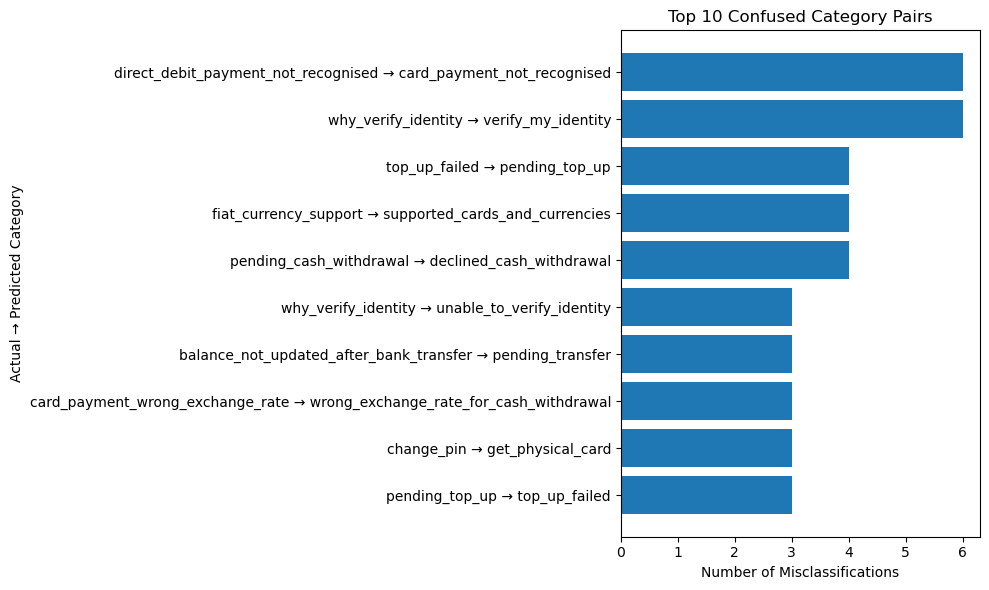

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the 10 most frequent actual-predicted confusion pairs
top_pairs = confusion_pairs.head(10).copy()

top_pairs["Pair"] = (
    top_pairs["Actual Category"]
    + " → "
    + top_pairs["Predicted Category"]
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_pairs["Pair"][::-1],
    top_pairs["Count"][::-1]
)

plt.xlabel("Number of Misclassifications")
plt.ylabel("Actual → Predicted Category")
plt.title("Top 10 Confused Category Pairs")
plt.tight_layout()
plt.show()

## Final Model Training

After comparing multiple machine learning models and evaluating the Linear SVM using a validation set, we selected `LinearSVC` with `C = 0.5`.

We will now train the selected model on the complete original training dataset. The TF-IDF vectorizer will also be fitted on the complete training text so that both the model and vectorizer are ready for future predictions.

The provided test dataset will not be used for this training step.

In [86]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# Prepare the complete training data
X_train_final_text = train_df["clean_text"]
y_train_final = train_df["category"]

# Fit TF-IDF on the complete training text
tfidf_final = TfidfVectorizer()
X_train_final_tfidf = tfidf_final.fit_transform(X_train_final_text)

# Train the selected Linear SVM model
final_svm_model = LinearSVC(C=0.5, random_state=42)
final_svm_model.fit(X_train_final_tfidf, y_train_final)

print("Final model training completed!")
print("Training samples:", X_train_final_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_final_tfidf.shape[1])
print("Number of categories:", len(final_svm_model.classes_))

Final model training completed!
Training samples: 10003
Number of TF-IDF features: 2320
Number of categories: 77


## Saving the Final Model and TF-IDF Vectorizer

We will save the trained Linear SVM model and the fitted TF-IDF vectorizer using Joblib.

The saved files can be loaded later by the prediction application to classify new customer support tickets without retraining the model.

In [87]:
import joblib
import os

# Create a folder for the saved model files
os.makedirs("models", exist_ok=True)

# Save the trained model
joblib.dump(final_svm_model, "models/final_svm_model.pkl")

# Save the fitted TF-IDF vectorizer
joblib.dump(tfidf_final, "models/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")
print("Saved files:")
print(os.listdir("models"))

Model and TF-IDF vectorizer saved successfully!
Saved files:
['final_svm_model.pkl', 'tfidf_vectorizer.pkl']


## Testing the Saved Model on a New Ticket

We will load the saved Linear SVM model and TF-IDF vectorizer, then use them to predict the category of a new customer support ticket.

This checks whether the saved artifacts can be used for inference without retraining the model.

In [88]:
import joblib

# Load the saved model and vectorizer
loaded_model = joblib.load("models/final_svm_model.pkl")
loaded_vectorizer = joblib.load("models/tfidf_vectorizer.pkl")

# Example of a new customer ticket
new_ticket = ["my card is not working"]

# Convert the ticket into TF-IDF features
ticket_features = loaded_vectorizer.transform(new_ticket)

# Predict the category
predicted_category = loaded_model.predict(ticket_features)

print("Customer Ticket:", new_ticket[0])
print("Predicted Category:", predicted_category[0])

Customer Ticket: my card is not working
Predicted Category: card_not_working
